# 03 — Which variables drive yield? (RQ2) — and is the effect linear? (RQ3)

Four views of importance, which answer slightly different questions:

| Method | Model | Question it answers |
|---|---|---|
| Standardised coefficients | `multiple_lr` | How much does yield change per 1 SD of a feature, *assuming a straight line*? |
| Lasso selection | `lasso` | Which features survive an L1 penalty? |
| Permutation importance | `best_overall` | How much worse do test predictions get if a feature is scrambled? |
| SHAP | `best_tree` (XGBoost) | How much does each feature move each individual prediction, including curved effects? |

**Reminder:** the Kaggle data is a synthetic benchmark (notebook 01). These
rankings describe the data generator, not real agronomy — and they are
associations, not causal effects.

In [1]:
import json
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))  # make `src` importable when run from notebooks/

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap

from src import config
from src.data import load_split, split_xy
from src.eda import top_pearson_feature
from src.explain import (
    agreement_table,
    grouped_importance,
    mean_abs_shap,
    permutation_table,
    rank_correlations,
    standardized_coefficients,
    tree_shap,
)
from src.models import get_linear_models
from src.plots import axis_label, save_figure

pd.set_option("display.width", 200)
train, test = load_split()
X_train, y_train = split_xy(train)
X_test, y_test = split_xy(test)
names = json.loads((config.MODELS_DIR / "model_names.json").read_text())
best_overall = joblib.load(config.MODELS_DIR / "best_overall.joblib")
best_tree = joblib.load(config.MODELS_DIR / "best_tree.joblib")
print("best_overall:", names["best_overall"], "| best_tree:", names["best_tree"])

linear_models = get_linear_models(top_pearson_feature(train))
multiple_lr = linear_models["multiple_lr"].fit(X_train, y_train)
lasso = linear_models["lasso"].fit(X_train, y_train)
TOP_N = 15

best_overall: polynomial | best_tree: gradient_boost


## 1. Standardised coefficients (`multiple_lr`)

,label,coef
0,fertilizer_amount,0.8793
1,pesticide_usage,-0.2652
2,total_rainfall,0.2142
3,soil_moisture,0.0682
4,crop_type = Wheat (vs Barley),-0.0659
5,crop_type = Rice (vs Barley),-0.0657
6,avg_temperature,-0.0627
7,nitrogen_content,0.0605
8,potassium_content,0.0565
9,region = South (vs Central),-0.0436


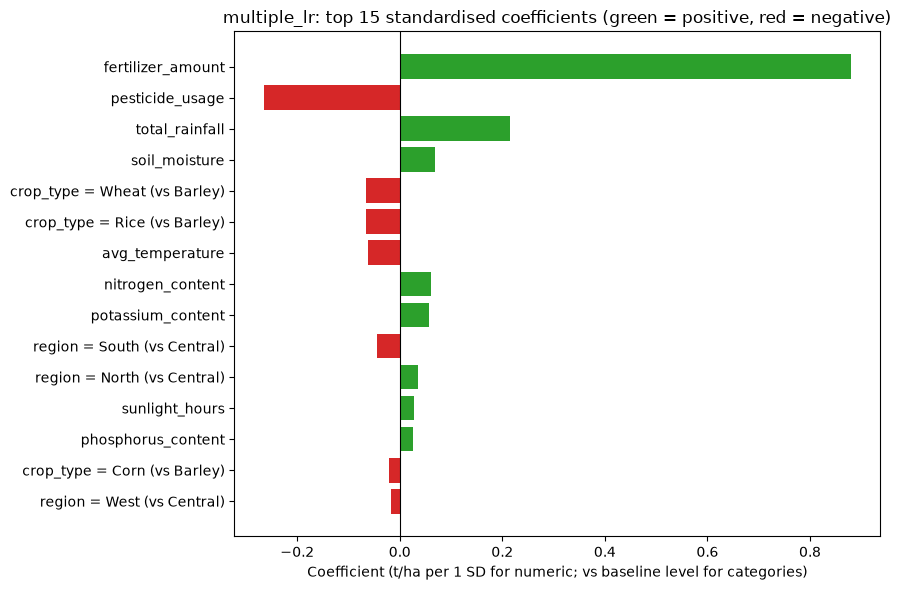

In [2]:
coefs = standardized_coefficients(multiple_lr, config.FEATURES)
top = coefs.head(TOP_N).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(top["label"], top["coef"], color=np.where(top["coef"] > 0, "tab:green", "tab:red"))
ax.axvline(0, color="black", lw=0.8)
ax.set(
    xlabel="Coefficient (t/ha per 1 SD for numeric; vs baseline level for categories)",
    title=f"multiple_lr: top {TOP_N} standardised coefficients (green = positive, red = negative)",
)
save_figure(fig, "explain_coefficients")
coefs.head(TOP_N)[["label", "coef"]].round(4)

**Interpretation.** `fertilizer_amount` dominates (≈ +0.88 t/ha per SD), followed
by `pesticide_usage` (negative) and `total_rainfall` (positive). Next come small
soil and weather effects (soil moisture, nitrogen, potassium, temperature),
each ≈ ±0.06 t/ha per SD. Category effects (crop, region, season versus their
baseline level) are the same size or smaller and mostly not significant (see
notebook 02). Coefficients are only as good as the straight-line assumption:
pH gets a coefficient near zero even though notebook 01 found an optimum.

## 2. Permutation importance (`best_overall`, test split)

,feature,rmse_increase,rmse_increase_std
0,fertilizer_amount,0.7343,0.0156
1,pesticide_usage,0.1161,0.0030
2,total_rainfall,0.0685,0.0081
3,soil_moisture,0.0092,0.0023
4,avg_temperature,0.0081,0.0027
5,nitrogen_content,0.0077,0.0021
6,potassium_content,0.0073,0.0017
7,soil_ph,0.0068,0.0015
8,phosphorus_content,0.0023,0.0013
9,sunlight_hours,0.0022,0.0010


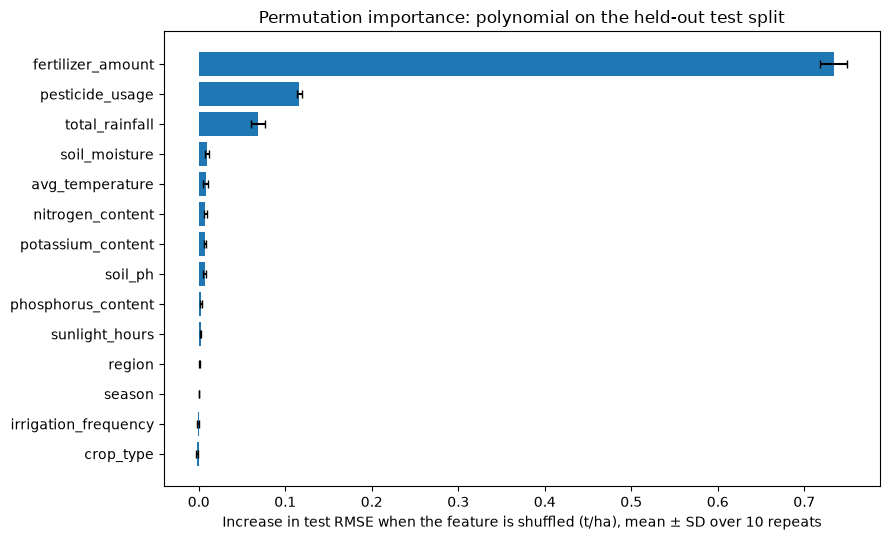

In [3]:
perm = permutation_table(best_overall, X_test, y_test)
fig, ax = plt.subplots(figsize=(9, 5.5))
p = perm.iloc[::-1]
ax.barh(p["feature"], p["rmse_increase"], xerr=p["rmse_increase_std"], color="tab:blue", capsize=3)
ax.set(
    xlabel="Increase in test RMSE when the feature is shuffled (t/ha), mean ± SD over 10 repeats",
    title=f"Permutation importance: {names['best_overall']} on the held-out test split",
)
save_figure(fig, "explain_permutation")
perm.round(4)

**Interpretation.** Shuffling `fertilizer_amount` destroys most of the
model's accuracy: test RMSE rises by ≈ 0.73 t/ha (printed above).
Pesticide and rainfall follow at a much lower level. The small soil and weather
terms each add only hundredths of a t/ha, and the context variables are about
0 or slightly negative, i.e. within noise. Because this measures the
*fitted polynomial model* on unseen data, it captures curved effects too. Soil
pH (rank 8) ranks above sunlight and phosphorus, whose linear coefficients are
about twice as large as pH's.

## 3. SHAP for the best tree model (XGBoost)

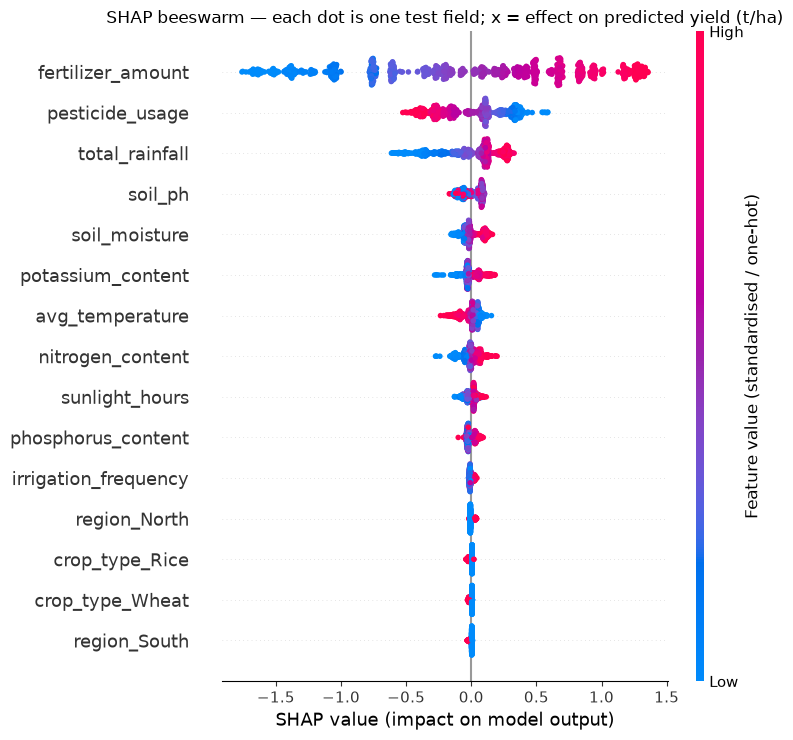

In [4]:
shap_inputs, model_inputs, shap_by_feature = tree_shap(best_tree, X_test, config.FEATURES)
fig = plt.figure()
shap.summary_plot(shap_inputs.to_numpy(), model_inputs, max_display=TOP_N, show=False)
plt.gcf().axes[-1].set_ylabel("Feature value (standardised / one-hot)")
plt.title("SHAP beeswarm — each dot is one test field; x = effect on predicted yield (t/ha)")
save_figure(plt.gcf(), "explain_shap_beeswarm")

fertilizer_amount       0.7455
pesticide_usage         0.2413
total_rainfall          0.1843
soil_ph                 0.0674
soil_moisture           0.0580
potassium_content       0.0524
avg_temperature         0.0488
nitrogen_content        0.0478
sunlight_hours          0.0331
phosphorus_content      0.0288
crop_type               0.0156
region                  0.0142
irrigation_frequency    0.0129
season                  0.0037
dtype: float32

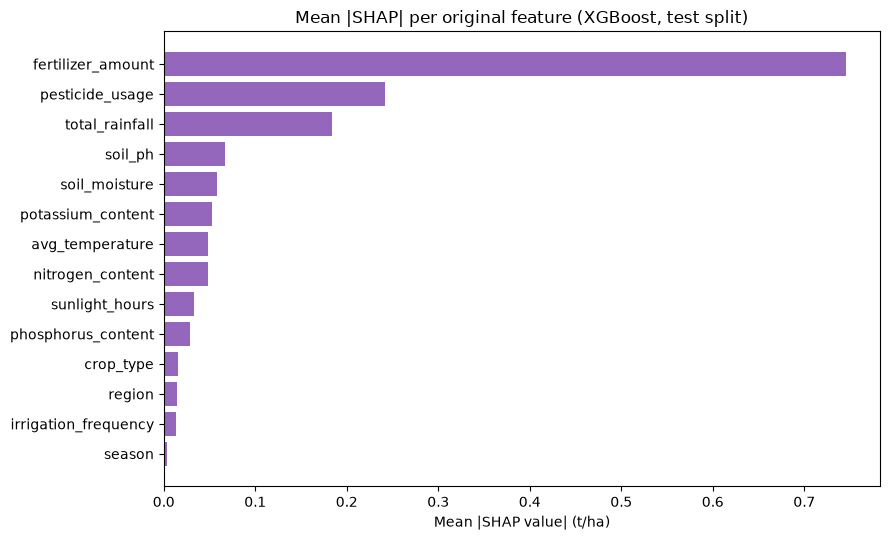

In [5]:
shap_importance = mean_abs_shap(shap_by_feature)
fig, ax = plt.subplots(figsize=(9, 5.5))
s = shap_importance.iloc[::-1]
ax.barh(s.index, s.to_numpy(), color="tab:purple")
ax.set(xlabel="Mean |SHAP value| (t/ha)", title="Mean |SHAP| per original feature (XGBoost, test split)")
save_figure(fig, "explain_shap_bar")
shap_importance.round(4)

**Interpretation.** The beeswarm shows direction as well as size. High
fertilizer (red dots) pushes predictions up by up to ≈ +1.4 t/ha, and low
fertilizer pushes them down by up to ≈ −1.8 t/ha. High pesticide and high
temperature push yield down. High rainfall, soil moisture, nitrogen and
potassium push it up. For soil pH, *middle* values (purple) sit on the
positive side and both extremes on the negative side, which is the optimum
again. Crop, region and season dummies cluster at 0. The top 3 by mean |SHAP|
are the same as by permutation, and pH climbs to 4th.

### SHAP dependence plots — what shape does each effect have?

The top 3 features by mean |SHAP|, plus every other feature notebook 01 flagged
as curved.

fertilizer_amount    mean SHAP by quintile of x: [-1.299, -0.51, 0.12, 0.613, 1.111]
pesticide_usage      mean SHAP by quintile of x: [0.359, 0.2, 0.029, -0.208, -0.351]
total_rainfall       mean SHAP by quintile of x: [-0.37, -0.067, 0.092, 0.126, 0.264]
phosphorus_content   mean SHAP by quintile of x: [-0.016, -0.026, -0.027, 0.029, 0.033]
soil_ph              mean SHAP by quintile of x: [-0.087, 0.003, 0.084, 0.055, -0.066]


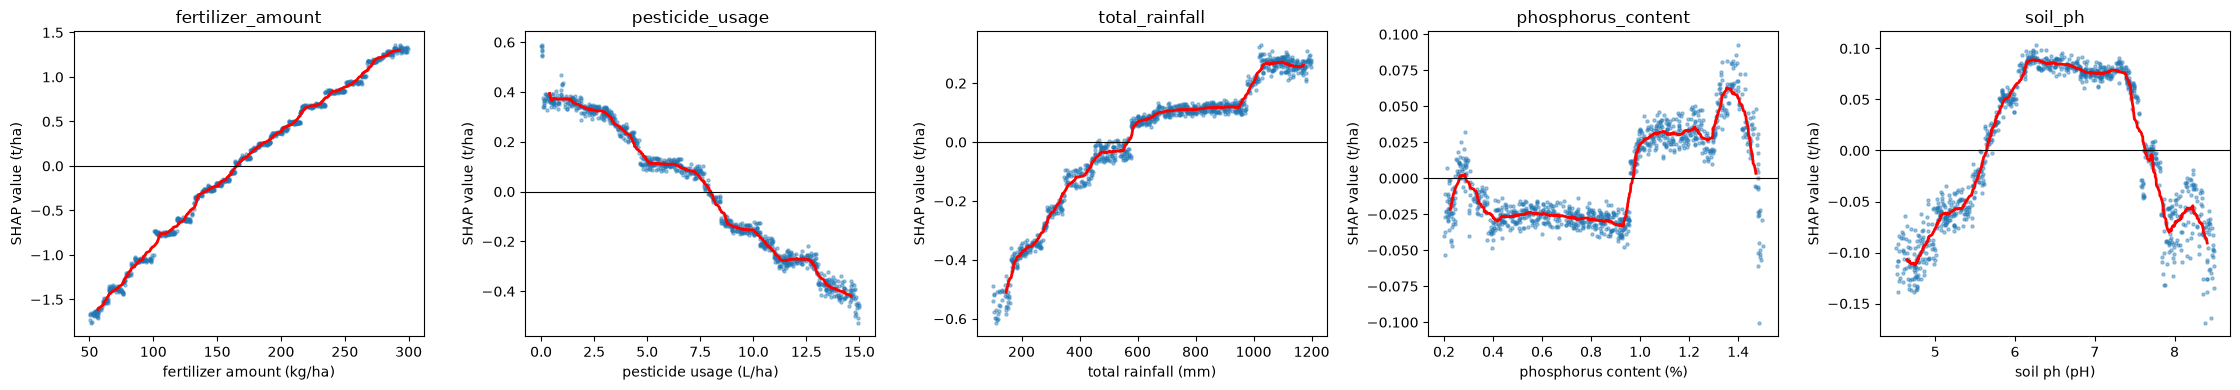

In [6]:
signal = pd.read_csv(config.TABLES_DIR / "feature_signal.csv", index_col="feature")
curved = signal.index[signal["p_quadratic"] < 0.05 / len(config.NUMERIC_FEATURES)]
numeric_by_shap = [f for f in shap_importance.index if f in config.NUMERIC_FEATURES]
dependence_features = numeric_by_shap[:3] + [f for f in curved if f not in numeric_by_shap[:3]]
fig, axes = plt.subplots(1, len(dependence_features), figsize=(4.5 * len(dependence_features), 4))
for ax, col in zip(axes, dependence_features):
    order = np.argsort(X_test.loc[shap_by_feature.index, col].to_numpy())
    xs = X_test.loc[shap_by_feature.index, col].to_numpy()[order]
    ys = shap_by_feature[col].to_numpy()[order]
    ax.scatter(xs, ys, s=5, alpha=0.4)
    window = 51  # rolling mean over 51 neighbouring fields to show the trend
    ax.plot(xs, pd.Series(ys).rolling(window, center=True).mean(), color="red", lw=2)
    ax.axhline(0, color="black", lw=0.8)
    ax.set(xlabel=axis_label(col), ylabel="SHAP value (t/ha)", title=col)
save_figure(fig, "explain_shap_dependence")
for col in dependence_features:
    b = pd.DataFrame({"x": X_test.loc[shap_by_feature.index, col], "s": shap_by_feature[col]})
    b["bin"] = pd.qcut(b["x"], 5, labels=False, duplicates="drop")
    quintile_means = b.groupby("bin")["s"].mean().astype(float).round(3).tolist()
    print(f"{col:20s} mean SHAP by quintile of x: {quintile_means}")

**Interpretation — shapes (direct evidence for RQ3):**

* `fertilizer_amount`: **near-linear and rising, with slight diminishing
  returns.** The gaps between quintile means shrink from ≈ 0.8 to ≈ 0.5 t/ha.
  The line spans ≈ 3 t/ha from lowest to highest dose, the largest effect by far.
* `pesticide_usage`: **falling, roughly linear**, from ≈ +0.4 to ≈ −0.4 t/ha.
  XGBoost fits it as a staircase of small steps.
* `total_rainfall`: **saturating.** Yield rises steeply up to ≈ 600 mm, then
  flattens (with a small step near 1,000 mm).
* `soil_ph`: **a flat-topped optimum between pH ≈ 6 and 7.5** (+0.08 t/ha),
  falling to ≈ −0.1 t/ha in acidic (< 5.5) and alkaline (> 7.8) soils. This is
  agronomically plausible. A linear model gives pH a coefficient of ≈ 0, but
  the tree model recovers the shape.
* `phosphorus_content`: **a tiny threshold near 0.95 %** (±0.03 t/ha), not
  the U-shape suggested in notebook 01. The effect is negligible, consistent
  with notebook 02, where its residual pattern was indistinguishable from noise.

**RQ3 verdict:** the relationship is **mostly linear** (fertilizer and
pesticide), with **mild saturation** (rainfall, fertilizer) and **one
optimum** (pH). The non-linear parts are small (≈ 0.1–0.3 t/ha) next to
fertilizer's ≈ 3 t/ha range, and there are no interactions (notebook 01).
That is why a degree-2 polynomial ties with gradient-boosted trees, and
neither beats plain linear regression by more than ≈ 0.007 t/ha RMSE.

## 4. Grouped importance — which *category* of factor matters most?

Farming    0.643
Weather    0.171
Soil       0.164
Context    0.022
Name: share, dtype: float32

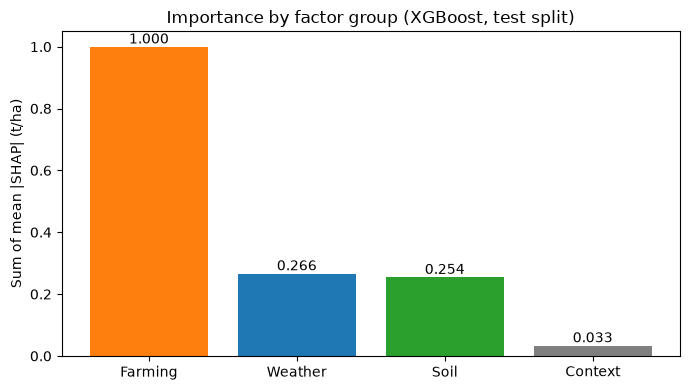

In [7]:
groups = grouped_importance(shap_importance, config.FEATURE_GROUPS)
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(groups.index, groups.to_numpy(), color=["tab:orange", "tab:blue", "tab:green", "tab:grey"])
ax.set(ylabel="Sum of mean |SHAP| (t/ha)", title="Importance by factor group (XGBoost, test split)")
for i, v in enumerate(groups.to_numpy()):
    ax.text(i, v, f"{v:.3f}", ha="center", va="bottom")
save_figure(fig, "explain_grouped_importance")
(groups / groups.sum()).round(3).rename("share")

**Interpretation.** **Farming practices** (fertilizer, pesticide, irrigation)
carry ≈ 64 % of the total mean |SHAP|. **Weather (≈ 17 %) and Soil (≈ 16 %) are
essentially tied for second.** Weather's share comes almost entirely from
rainfall; soil's comes from five small effects (pH, moisture, N, P, K).
Context (crop/region/season) contributes ≈ 2 %. In the real world crop type
would dominate, since crops have very different yield potentials. Its absence
here is a hallmark of the synthetic generator.

## 5. Do the methods agree? Rank agreement table

Categorical features have several coefficients (one per level); their score
is the **largest absolute coefficient among their levels**. A feature counts
as "selected" by Lasso if any of its terms is non-zero.

In [8]:
lasso_coefs = standardized_coefficients(lasso, config.FEATURES)
scores = {
    "abs_std_coef": coefs.groupby("feature")["abs_coef"].max(),
    "abs_lasso_coef": lasso_coefs.groupby("feature")["abs_coef"].max(),
    "permutation": perm.set_index("feature")["rmse_increase"],
    "mean_abs_shap": shap_importance,
}
lasso_selected = lasso_coefs.groupby("feature")["abs_coef"].max() > 0
agreement = agreement_table(scores, lasso_selected)
agreement.to_csv(config.TABLES_DIR / "importance_agreement.csv", index_label="feature")
agreement.round(4)

,abs_std_coef,abs_lasso_coef,permutation,mean_abs_shap,abs_std_coef_rank,abs_lasso_coef_rank,permutation_rank,mean_abs_shap_rank,lasso_selected
fertilizer_amount,0.8793,0.8767,0.7343,0.7455,1,1,1,1,True
pesticide_usage,0.2652,0.2625,0.1161,0.2413,2,2,2,2,True
total_rainfall,0.2142,0.2109,0.0685,0.1843,3,3,3,3,True
soil_moisture,0.0682,0.0654,0.0092,0.0580,4,4,4,5,True
crop_type,0.0659,0.0285,-0.0019,0.0156,5,8,14,11,True
avg_temperature,0.0627,0.0599,0.0081,0.0488,6,5,5,7,True
nitrogen_content,0.0605,0.0576,0.0077,0.0478,7,6,6,8,True
potassium_content,0.0565,0.0533,0.0073,0.0524,8,7,7,6,True
region,0.0436,0.0269,0.0009,0.0142,9,9,11,12,True
sunlight_hours,0.0273,0.0247,0.0022,0.0331,10,10,10,9,True


In [9]:
rho = rank_correlations(scores)
rho.round(3)

,abs_std_coef,abs_lasso_coef,permutation,mean_abs_shap
abs_std_coef,1.000,0.974,0.732,0.701
abs_lasso_coef,0.974,1.000,0.837,0.754
permutation,0.732,0.837,1.000,0.908
mean_abs_shap,0.701,0.754,0.908,1.000


**Interpretation.**

* **Consistently important under every method:** `fertilizer_amount` (rank 1),
  `pesticide_usage` (rank 2) and `total_rainfall` (rank 3). All four methods
  agree exactly on the top 3.
* **Consistently unimportant:** `irrigation_frequency` and `season` (ranks
  12–14 everywhere).
* **Disagreement 1, `soil_ph`:** rank 13 by both linear methods, but rank 8
  by permutation and **rank 4 by SHAP**. The most likely reason is that pH's
  effect is an optimum, and a straight line through an inverted-U has a slope
  of ≈ 0. Flexible models see the effect and linear coefficients cannot.
* **Disagreement 2, `crop_type` (and `region`):** rank 5 by |coefficient| but
  rank 14 by permutation. A categorical's coefficient score is the *largest of
  several dummy coefficients*, and taking the maximum of four noisy estimates
  inflates it (Rice/Wheat reach only p ≈ 0.04, notebook 02). Permutation
  importance on unseen data shows crop type adds nothing to accuracy. Lasso
  marks these features "selected" because one tiny level survives, which shows
  Lasso selection alone is a weak importance signal.
* **Rank correlations** (table above) form two families. The two coefficient
  methods agree almost perfectly (ρ ≈ 0.97), and permutation and SHAP agree
  strongly (ρ ≈ 0.91). Across families ρ ≈ 0.70–0.84, and the gap is explained
  by the two disagreements above.

## Summary (RQ2)

Yield in this benchmark is most strongly associated with **fertilizer**, then
**pesticide (negative)** and **rainfall**. All four methods agree on this top 3, farming
practices carry ≈ 64 % of the importance, and crop/region/season add
essentially nothing. The main systematic disagreement, soil pH, is itself
evidence for RQ3: its effect is an optimum, which linear coefficients cannot
see.